In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import models
from tensorflow.keras.layers import LSTM , Dense , Input

In [ ]:
# Data :  sequence of 4 numbers -->  predict next one
X  =  np.array([[[i+j] for j in range (4)]for i in range(1,50)],dtype='float32')/50
y=  np.array([[i+4] for i in range(1,50)],dtype="float32")/50

In [ ]:
print("Shape of x is ",X.shape)
print("shape of y is ",y.shape)

Shape of x is  (49, 4, 1)
shape of y is  (49, 1)


In [ ]:
model = models.Sequential([
    Input(shape=(4,1)), #  4 time steps , 1 feature
    LSTM(16),   #   returnn the last hidden state
    Dense(1)  #  predicts the next value

    ])

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(0.01),loss="mse")
trained_model=model.fit(X,y, epochs=300,verbose=0)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,509 (13.71 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,340 (9.14 KB)

In [ ]:
for layer in model.layers:
  print("Layer name" , layer.name ,  "|" ,  type(layer).__name__ , "|", layer.count_params() , "trainable weights",sum(tf.size(w).numpy() for w in model.trainable_weights) )

Layer name lstm | LSTM | 1152 trainable weights 1169
Layer name dense | Dense | 17 trainable weights 1169


see the actual weight valus

In [ ]:
for layer in model.layers:
  for w  in layer.weights:
    print(layer.name,w.name,w.shape)

lstm kernel (1, 64)
lstm recurrent_kernel (16, 64)
lstm bias (64,)
dense kernel (16, 1)
dense bias (1,)


In [ ]:
# values of one layer as numpy array
emb_weights = model.layers[0]. get_weights()[0]
emb_weights.shape

(1, 64)

## layer configuration

In [ ]:
model.layers[1].get_config()

{'name': 'dense',
 'trainable': True,
 'dtype': {'module': 'keras',
  'class_name': 'DTypePolicy',
  'config': {'name': 'float32'},
  'registered_name': None},
 'units': 1,
 'activation': 'linear',
 'use_bias': True,
 'kernel_initializer': {'module': 'keras.initializers',
  'class_name': 'GlorotUniform',
  'config': {'seed': None},
  'registered_name': None},
 'bias_initializer': {'module': 'keras.initializers',
  'class_name': 'Zeros',
  'config': {},
  'registered_name': None},
 'kernel_regularizer': None,
 'bias_regularizer': None,
 'kernel_constraint': None,
 'bias_constraint': None,
 'quantization_config': None}

In [ ]:
## visual diagram of the model

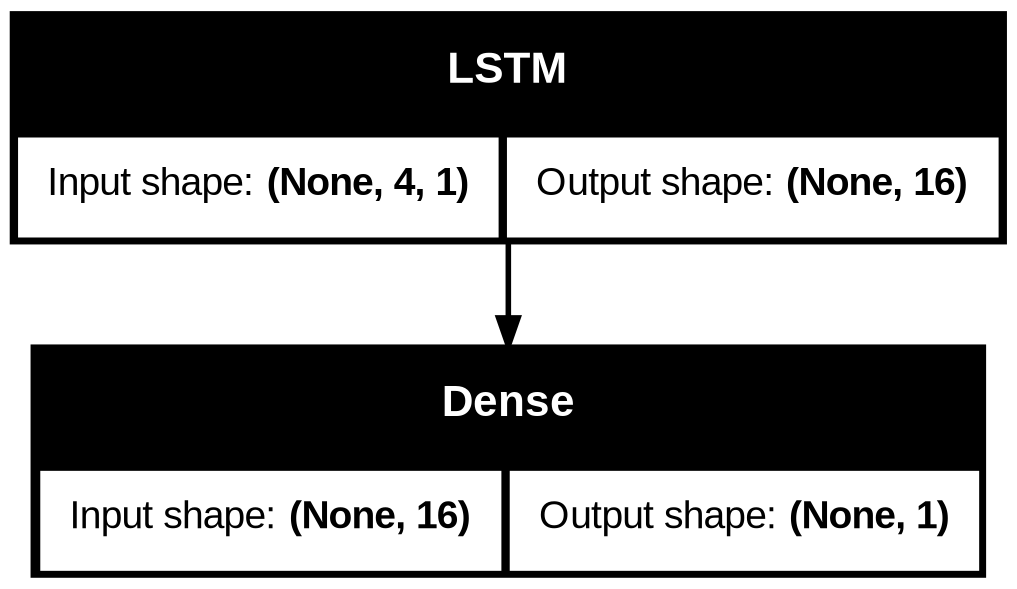

In [ ]:
tf.keras.utils.plot_model(model,show_shapes=True, to_file="model.png")

In [ ]:
trained_model.history.keys()

dict_keys(['loss'])

In [ ]:
trained_model.history["loss"][:10]

[0.0034583357628434896,
 0.001551042078062892,
 0.007112125400453806,
 0.0005147082265466452,
 0.003137273946776986,
 0.0017951552290469408,
 0.00026974963839165866,
 0.0017589096678420901,
 0.0007288326742127538,
 0.00022277483367361128]

### test model

In [ ]:
test = np.array([[[10],[11],[12],[13]]],dtype="float32")/50
print(model.predict(test,verbose=1)[0][0]*50)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
14.032812
